In [1]:
import sys

if "google.colab" in sys.modules:
    %pip install teachopencadd --no-deps -q
    !teachopencadd -d 1
    %pip uninstall teachopencadd -y -q
    %pip install -qr requirements.txt

In [2]:
if "google.colab" in sys.modules:
    %pip install teachopencadd --no-deps -q
    !teachopencadd -d 1
    %pip uninstall teachopencadd -y -q
    %pip install -qr requirements.txt

In [3]:
import math

In [4]:
from pathlib import Path

In [5]:
from zipfile import ZipFile

In [6]:
from tempfile import TemporaryDirectory

In [7]:
import numpy as np

In [8]:
import pandas as pd

In [9]:
#pip install rdkit

In [10]:
from rdkit.Chem import PandasTools

In [11]:
!pip install chembl_webresource_client

In [12]:
from chembl_webresource_client.new_client import new_client

C:\Users\PC\anaconda3\Lib\site-packages\chembl_webresource_client\__init__.py:4: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  __version__ = __import__('pkg_resources').get_distribution('chembl_webresource_client').version


In [13]:
from tqdm.auto import tqdm

In [14]:
HERE = Path(_dh[-1])
DATA = HERE / "data"

In [15]:
#resource objects for API access
targets_api = new_client.target
compounds_api = new_client.molecule
bioactivities_api = new_client.activity

In [16]:
type(targets_api)

chembl_webresource_client.query_set.QuerySet

In [17]:
type(compounds_api)

chembl_webresource_client.query_set.QuerySet

#### EGFR kinase

In [18]:
uniprot_id = "P00533"

In [19]:
# Get target information from ChEMBL but restrict it to specified values only
targets = targets_api.get(target_components__accession=uniprot_id).only(
    "target_chembl_id", "organism", "pref_name", "target_type"
)

In [20]:
print(f'The type of the targets is "{type(targets)}"')

The type of the targets is "<class 'chembl_webresource_client.query_set.QuerySet'>"


In [21]:
##(pd.DataFrame(targets)).head

##### Download target data from ChEMBL¶
The results of the query are stored in targets, a QuerySet,(the results are not fetched from ChEMBL until we ask for it here using 
    pandas.DataFrame.from_records).

targets = pd.DataFrame.from_records(targets)
targets

In [22]:
targets = pd.DataFrame.from_records(targets)

In [23]:
#targets

In [24]:
targets.shape

(17, 4)

In [25]:
type(targets)

pandas.core.frame.DataFrame

In [26]:
#targets[0]

In [27]:
targets.head()

,organism,pref_name,target_chembl_id,target_type
0,Homo sapiens,Epidermal growth factor receptor,CHEMBL203,SINGLE PROTEIN
1,Homo sapiens,Epidermal growth factor receptor,CHEMBL203,SINGLE PROTEIN
2,Homo sapiens,Epidermal growth factor receptor and ErbB2 (HE...,CHEMBL2111431,PROTEIN FAMILY
3,Homo sapiens,Epidermal growth factor receptor,CHEMBL2363049,PROTEIN FAMILY
4,Homo sapiens,MER intracellular domain/EGFR extracellular do...,CHEMBL3137284,CHIMERIC PROTEIN


#### Select target (target ChEMBL ID)

In [28]:
#df.iloc[row_selector, column_selector]
#to get the 1st row
target = targets.iloc[0]


In [29]:
target

organism                                Homo sapiens
pref_name           Epidermal growth factor receptor
target_chembl_id                           CHEMBL203
target_type                           SINGLE PROTEIN
Name: 0, dtype: object

In [30]:
chembl_id = target.target_chembl_id

In [31]:
print(f"The target ChEMBL ID of interest is {chembl_id}")

The target ChEMBL ID of interest is CHEMBL203


#### Get bioactivity data
###### Fetch bioactivity data for the target from ChEMBL and filter it to only consider
-human proteins,

-bioactivity type IC50,

-exact measurements (relation '='), and

-binding data (assay type 'B').

In [32]:
bioactivities = bioactivities_api.filter(
    target_chembl_id=chembl_id, type="IC50", relation="=", assay_type="B"    
).only(
    "activity_id",
    "assay_chembl_id",
    "assay_description",
    "assay_type",
    "molecule_chembl_id",
    "type",
    "standard_units",
    "relation",
    "standard_value",
    "target_chembl_id",
    "target_organism",
)

In [33]:
print(f"Length and type of bioactivities object: {len(bioactivities)}, {type(bioactivities)}")

Length and type of bioactivities object: 17686, <class 'chembl_webresource_client.query_set.QuerySet'>


In [34]:
#first element
print(f"Length and type of first element: {len(bioactivities[0])}, {type(bioactivities[0])}")
bioactivities[0]

Length and type of first element: 13, <class 'dict'>


{'activity_id': 32260,
 'assay_chembl_id': 'CHEMBL674637',
 'assay_description': 'Inhibitory activity towards tyrosine phosphorylation for the epidermal growth factor-receptor kinase',
 'assay_type': 'B',
 'molecule_chembl_id': 'CHEMBL68920',
 'relation': '=',
 'standard_units': 'nM',
 'standard_value': '41.0',
 'target_chembl_id': 'CHEMBL203',
 'target_organism': 'Homo sapiens',
 'type': 'IC50',
 'units': 'uM',
 'value': '0.041'}

#### Download bioactivity data from ChEMB

In [35]:
type(bioactivities)

chembl_webresource_client.query_set.QuerySet

#download the QuerySet in the form of a pandas DataFrame
bioactivities_df = pd.DataFrame.from_dict(bioactivities)

In [36]:
# replace first line in cell below with this other line
bioactivities_df = pd.read_csv(r"C:\Users\PC\OneDrive\Attachments\Desktop\Bioinformatics\TeachOpenCADD\EGFR_bioactivities_CHEMBL27.csv.zip" , index_col=0)

In [37]:
print(f"DataFrame shape: {bioactivities_df.shape}")

DataFrame shape: (7178, 13)


In [38]:
bioactivities_df.head()

,activity_id,assay_chembl_id,assay_description,assay_type,molecule_chembl_id,relation,standard_units,standard_value,target_chembl_id,target_organism,type,units,value
0,32260,CHEMBL674637,Inhibitory activity towards tyrosine phosphory...,B,CHEMBL68920,=,nM,41.0,CHEMBL203,Homo sapiens,IC50,uM,0.041
1,32260,CHEMBL674637,Inhibitory activity towards tyrosine phosphory...,B,CHEMBL68920,=,nM,41.0,CHEMBL203,Homo sapiens,IC50,uM,0.041
2,32267,CHEMBL674637,Inhibitory activity towards tyrosine phosphory...,B,CHEMBL69960,=,nM,170.0,CHEMBL203,Homo sapiens,IC50,uM,0.170
3,32680,CHEMBL677833,In vitro inhibition of Epidermal growth factor...,B,CHEMBL137635,=,nM,9300.0,CHEMBL203,Homo sapiens,IC50,uM,9.300
4,32770,CHEMBL674643,Inhibitory concentration of EGF dependent auto...,B,CHEMBL306988,=,nM,500000.0,CHEMBL203,Homo sapiens,IC50,uM,500.000


In [39]:
# the different units
bioactivities_df["units"].unique()

array(['uM', 'nM', 'pM', 'M', "10'3 uM", "10'1 ug/ml", 'ug ml-1',
       "10'-1microM", "10'1 uM", "10'-1 ug/ml", "10'-2 ug/ml", "10'2 uM",
       "10'-3 ug/ml", "10'-2microM", '/uM', "10'-6g/ml", 'mM', 'umol/L',
       'nmol/L', "10'-10M"], dtype=object)

In [40]:
bioactivities_df.drop(["units", "value"], axis=1, inplace=True)

In [41]:
bioactivities_df.head()

,activity_id,assay_chembl_id,assay_description,assay_type,molecule_chembl_id,relation,standard_units,standard_value,target_chembl_id,target_organism,type
0,32260,CHEMBL674637,Inhibitory activity towards tyrosine phosphory...,B,CHEMBL68920,=,nM,41.0,CHEMBL203,Homo sapiens,IC50
1,32260,CHEMBL674637,Inhibitory activity towards tyrosine phosphory...,B,CHEMBL68920,=,nM,41.0,CHEMBL203,Homo sapiens,IC50
2,32267,CHEMBL674637,Inhibitory activity towards tyrosine phosphory...,B,CHEMBL69960,=,nM,170.0,CHEMBL203,Homo sapiens,IC50
3,32680,CHEMBL677833,In vitro inhibition of Epidermal growth factor...,B,CHEMBL137635,=,nM,9300.0,CHEMBL203,Homo sapiens,IC50
4,32770,CHEMBL674643,Inhibitory concentration of EGF dependent auto...,B,CHEMBL306988,=,nM,500000.0,CHEMBL203,Homo sapiens,IC50


#### Preprocess and filter bioactivity data

In [42]:
##### Convert standard_value’s datatype from object to float

In [43]:
#bioactivities_df = bioactivities_df.astype({"standard_value": "float64"})

In [44]:
bioactivities_df.dtypes

activity_id             int64
assay_chembl_id        object
assay_description      object
assay_type             object
molecule_chembl_id     object
relation               object
standard_units         object
standard_value        float64
target_chembl_id       object
target_organism        object
type                   object
dtype: object

In [45]:
bioactivities_df.dtypes["standard_value"]

dtype('float64')

In [46]:
##### Delete entries with missing values

In [47]:
bioactivities_df.dropna(axis=0, how="any",inplace=True)

In [48]:
#with no missin value--remained
print(f"DataFrame shape: {bioactivities_df.shape}")

DataFrame shape: (7177, 11)


In [49]:
##### Keep only entries with “standard_unit == nM”

In [50]:
bioactivities_df['standard_units'].unique()

array(['nM', 'ug.mL-1', '/uM'], dtype=object)

In [51]:
print(f"Units in downloaded data: {bioactivities_df['standard_units'].unique()}")

Units in downloaded data: ['nM' 'ug.mL-1' '/uM']


In [52]:
print(f"Number of non-nM entries: {bioactivities_df[bioactivities_df['standard_units']!= 'nM'].shape[0]}")

Number of non-nM entries: 64


In [53]:
bioactivities_df = bioactivities_df[bioactivities_df["standard_units"] == "nM"]
print(f"Units after filtering: {bioactivities_df['standard_units'].unique()}")

Units after filtering: ['nM']


In [54]:
print(f"DataFrame shape: {bioactivities_df.shape}")

DataFrame shape: (7113, 11)


In [55]:
##### Delete duplicate molecules

In [56]:
bioactivities_df.head(2)

,activity_id,assay_chembl_id,assay_description,assay_type,molecule_chembl_id,relation,standard_units,standard_value,target_chembl_id,target_organism,type
0,32260,CHEMBL674637,Inhibitory activity towards tyrosine phosphory...,B,CHEMBL68920,=,nM,41.0,CHEMBL203,Homo sapiens,IC50
1,32260,CHEMBL674637,Inhibitory activity towards tyrosine phosphory...,B,CHEMBL68920,=,nM,41.0,CHEMBL203,Homo sapiens,IC50


In [57]:
bioactivities_df.shape

(7113, 11)

In [58]:
bioactivities_df.drop_duplicates("molecule_chembl_id", keep="first",inplace=True)

In [59]:
print(f"DataFrame shape: {bioactivities_df.shape}")

DataFrame shape: (5451, 11)


In [60]:
bioactivities_df.head()

,activity_id,assay_chembl_id,assay_description,assay_type,molecule_chembl_id,relation,standard_units,standard_value,target_chembl_id,target_organism,type
0,32260,CHEMBL674637,Inhibitory activity towards tyrosine phosphory...,B,CHEMBL68920,=,nM,41.0,CHEMBL203,Homo sapiens,IC50
2,32267,CHEMBL674637,Inhibitory activity towards tyrosine phosphory...,B,CHEMBL69960,=,nM,170.0,CHEMBL203,Homo sapiens,IC50
3,32680,CHEMBL677833,In vitro inhibition of Epidermal growth factor...,B,CHEMBL137635,=,nM,9300.0,CHEMBL203,Homo sapiens,IC50
4,32770,CHEMBL674643,Inhibitory concentration of EGF dependent auto...,B,CHEMBL306988,=,nM,500000.0,CHEMBL203,Homo sapiens,IC50
5,32772,CHEMBL674643,Inhibitory concentration of EGF dependent auto...,B,CHEMBL66879,=,nM,3000000.0,CHEMBL203,Homo sapiens,IC50


In [61]:
##### Reset “DataFrame” index

In [62]:
#drop=True--Discards the old index instead of saving it as a new column
#After deleting some rows,to reset the index to be continuous
bioactivities_df.reset_index(drop=True,inplace=True)

In [63]:
bioactivities_df.head()

,activity_id,assay_chembl_id,assay_description,assay_type,molecule_chembl_id,relation,standard_units,standard_value,target_chembl_id,target_organism,type
0,32260,CHEMBL674637,Inhibitory activity towards tyrosine phosphory...,B,CHEMBL68920,=,nM,41.0,CHEMBL203,Homo sapiens,IC50
1,32267,CHEMBL674637,Inhibitory activity towards tyrosine phosphory...,B,CHEMBL69960,=,nM,170.0,CHEMBL203,Homo sapiens,IC50
2,32680,CHEMBL677833,In vitro inhibition of Epidermal growth factor...,B,CHEMBL137635,=,nM,9300.0,CHEMBL203,Homo sapiens,IC50
3,32770,CHEMBL674643,Inhibitory concentration of EGF dependent auto...,B,CHEMBL306988,=,nM,500000.0,CHEMBL203,Homo sapiens,IC50
4,32772,CHEMBL674643,Inhibitory concentration of EGF dependent auto...,B,CHEMBL66879,=,nM,3000000.0,CHEMBL203,Homo sapiens,IC50


In [64]:
##### Rename columns

In [65]:
bioactivities_df.rename(columns={"standard_value": "IC50","standard_units": "units"}, inplace=True)

bioactivities_df.head(1)

In [66]:
print(f"DataFrame shape: {bioactivities_df.shape}")

DataFrame shape: (5451, 11)


#### Get compound data¶
We have a DataFrame containing all molecules tested against EGFR (with the respective measured bioactivity).

Next; to get the molecular structures of the molecules that are linked to respective bioactivity ChEMBL IDs

#### Fetch compound data from ChEMBL

In [67]:
#fetch compound ChEMBL IDs and structures for the compounds linked to our filtered bioactivity data
compounds_provider = compounds_api.filter(molecule_chembl_id__in=list(bioactivities_df["molecule_chembl_id"])).only("molecule_chembl_id", "molecule_structures")

#### Download compound data from ChEMBL

In [68]:
# export the QuerySet object into a pandas.DataFrame
# first obtain the list of records through tqdm, so we get a nice progress bar and some ETAs. 
# Which can then be pass the list of compounds to the DataFrame
compounds = list(tqdm(compounds_provider))

  0%|          | 0/5439 [00:00<?, ?it/s]

In [69]:
compounds_df = pd.DataFrame.from_records(compounds)

In [70]:
print(f"DataFrame shape: {compounds_df.shape}")

DataFrame shape: (5439, 2)


In [71]:
compounds_df.head()

,molecule_chembl_id,molecule_structures
0,CHEMBL6246,{'canonical_smiles': 'O=c1oc2c(O)c(O)cc3c(=O)o...
1,CHEMBL10,{'canonical_smiles': 'C[S+]([O-])c1ccc(-c2nc(-...
2,CHEMBL6976,{'canonical_smiles': 'COc1cc2c(cc1OC)Nc1ncn(C)...
3,CHEMBL7002,{'canonical_smiles': 'CC1(COc2ccc(CC3SC(=O)NC3...
4,CHEMBL414013,{'canonical_smiles': 'COc1cc2c(cc1OC)Nc1ncnc(O...


#### Preprocess and filter compound data

In [72]:
##### Remove entries with missing molecule structure entry

In [73]:
compounds_df.shape

(5439, 2)

In [74]:
compounds_df.dropna(axis=0, how="any", inplace=True)

In [75]:
print(f"DataFrame shape: {compounds_df.shape}")

DataFrame shape: (5432, 2)


In [76]:
##### Delete duplicate molecules

In [77]:
compounds_df.drop_duplicates("molecule_chembl_id", keep="first", inplace=True)

In [78]:
print(f"DataFrame shape: {compounds_df.shape}")

DataFrame shape: (5432, 2)


In [79]:
##### Get molecules with canonical SMILES

In [80]:
compounds_df

,molecule_chembl_id,molecule_structures
0,CHEMBL6246,{'canonical_smiles': 'O=c1oc2c(O)c(O)cc3c(=O)o...
1,CHEMBL10,{'canonical_smiles': 'C[S+]([O-])c1ccc(-c2nc(-...
2,CHEMBL6976,{'canonical_smiles': 'COc1cc2c(cc1OC)Nc1ncn(C)...
3,CHEMBL7002,{'canonical_smiles': 'CC1(COc2ccc(CC3SC(=O)NC3...
4,CHEMBL414013,{'canonical_smiles': 'COc1cc2c(cc1OC)Nc1ncnc(O...
...,...,...
5434,CHEMBL4293734,{'canonical_smiles': 'C=C=CC(=O)Nc1cc(Nc2nccc(...
5435,CHEMBL4294156,{'canonical_smiles': 'COc1cccc(Nc2cc(NC(=O)CCC...
5436,CHEMBL4294211,{'canonical_smiles': 'C=C=CC(=O)Nc1cc(Nc2nccc(...
5437,CHEMBL4294264,{'canonical_smiles': 'COc1cc2ncnc(Nc3ccc(-c4cc...


In [81]:
#compounds_df.iloc[0]

In [82]:
#compounds_df.loc[0]

In [83]:
compounds_df.iloc[0].molecule_structures.keys()

dict_keys(['canonical_smiles', 'molfile', 'standard_inchi', 'standard_inchi_key'])

In [84]:
#Create an empty list to collect the SMILES strings
canonical_smiles = []

#Loop over every row in the compounds DataFrame
#
for i, compounds in compounds_df.iterrows():
    try:
        # Access the nested dict inside the 'molecule_structures' cell,
        # then extract the 'canonical_smiles' key
        canonical_smiles.append(compounds["molecule_structures"]["canonical_smiles"])
    except KeyError:
        # If the key is missing (in some rows), store None instead
        canonical_smiles.append(None)

In [85]:
#Assign the collected list as a new flat column called smiles
compounds_df["smiles"] = canonical_smiles

In [86]:
compounds_df.head

<bound method NDFrame.head of      molecule_chembl_id                                molecule_structures  \
0            CHEMBL6246  {'canonical_smiles': 'O=c1oc2c(O)c(O)cc3c(=O)o...   
1              CHEMBL10  {'canonical_smiles': 'C[S+]([O-])c1ccc(-c2nc(-...   
2            CHEMBL6976  {'canonical_smiles': 'COc1cc2c(cc1OC)Nc1ncn(C)...   
3            CHEMBL7002  {'canonical_smiles': 'CC1(COc2ccc(CC3SC(=O)NC3...   
4          CHEMBL414013  {'canonical_smiles': 'COc1cc2c(cc1OC)Nc1ncnc(O...   
...                 ...                                                ...   
5434      CHEMBL4293734  {'canonical_smiles': 'C=C=CC(=O)Nc1cc(Nc2nccc(...   
5435      CHEMBL4294156  {'canonical_smiles': 'COc1cccc(Nc2cc(NC(=O)CCC...   
5436      CHEMBL4294211  {'canonical_smiles': 'C=C=CC(=O)Nc1cc(Nc2nccc(...   
5437      CHEMBL4294264  {'canonical_smiles': 'COc1cc2ncnc(Nc3ccc(-c4cc...   
5438      CHEMBL4294743  {'canonical_smiles': 'CCC(=O)N[C@H]1CC[C@H](N2...   

                                 

In [87]:
# Remove the now-redundant nested 'molecule_structures' column
compounds_df.drop("molecule_structures", axis=1, inplace=True)

In [88]:
compounds_df

,molecule_chembl_id,smiles
0,CHEMBL6246,O=c1oc2c(O)c(O)cc3c(=O)oc4c(O)c(O)cc1c4c23
1,CHEMBL10,C[S+]([O-])c1ccc(-c2nc(-c3ccc(F)cc3)c(-c3ccncc...
2,CHEMBL6976,COc1cc2c(cc1OC)Nc1ncn(C)c(=O)c1C2
3,CHEMBL7002,CC1(COc2ccc(CC3SC(=O)NC3=O)cc2)CCCCC1
4,CHEMBL414013,COc1cc2c(cc1OC)Nc1ncnc(O)c1C2
...,...,...
5434,CHEMBL4293734,C=C=CC(=O)Nc1cc(Nc2nccc(-c3cn(C)c4ccccc34)n2)c...
5435,CHEMBL4294156,COc1cccc(Nc2cc(NC(=O)CCCC(=O)O)ncn2)c1
5436,CHEMBL4294211,C=C=CC(=O)Nc1cc(Nc2nccc(-c3cn(C)c4ccccc34)n2)c...
5437,CHEMBL4294264,COc1cc2ncnc(Nc3ccc(-c4cc(-c5ccc(Br)cc5)c(C#N)c...


In [89]:
print(f"DataFrame shape: {compounds_df.shape}")

DataFrame shape: (5432, 2)


In [90]:
compounds_df

,molecule_chembl_id,smiles
0,CHEMBL6246,O=c1oc2c(O)c(O)cc3c(=O)oc4c(O)c(O)cc1c4c23
1,CHEMBL10,C[S+]([O-])c1ccc(-c2nc(-c3ccc(F)cc3)c(-c3ccncc...
2,CHEMBL6976,COc1cc2c(cc1OC)Nc1ncn(C)c(=O)c1C2
3,CHEMBL7002,CC1(COc2ccc(CC3SC(=O)NC3=O)cc2)CCCCC1
4,CHEMBL414013,COc1cc2c(cc1OC)Nc1ncnc(O)c1C2
...,...,...
5434,CHEMBL4293734,C=C=CC(=O)Nc1cc(Nc2nccc(-c3cn(C)c4ccccc34)n2)c...
5435,CHEMBL4294156,COc1cccc(Nc2cc(NC(=O)CCCC(=O)O)ncn2)c1
5436,CHEMBL4294211,C=C=CC(=O)Nc1cc(Nc2nccc(-c3cn(C)c4ccccc34)n2)c...
5437,CHEMBL4294264,COc1cc2ncnc(Nc3ccc(-c4cc(-c5ccc(Br)cc5)c(C#N)c...


In [91]:
#Remove all molecules without a canonical SMILES string
compounds_df.dropna(axis=0, how="any", inplace=True)

In [92]:
print(f"DataFrame shape: {compounds_df.shape}")

DataFrame shape: (5432, 2)


#### Output (bioactivity-compound) data

##### Summary of compound and bioactivity data

In [93]:
print(f"Bioactivities filtered: {bioactivities_df.shape[0]}")
bioactivities_df.columns

Bioactivities filtered: 5451


Index(['activity_id', 'assay_chembl_id', 'assay_description', 'assay_type',
       'molecule_chembl_id', 'relation', 'units', 'IC50', 'target_chembl_id',
       'target_organism', 'type'],
      dtype='object')

In [94]:
print(f"Compounds filtered: {compounds_df.shape[0]}")
compounds_df.columns

Compounds filtered: 5432


Index(['molecule_chembl_id', 'smiles'], dtype='object')

##### Merge both datasets
Merge values of interest from bioactivities_df and compounds_df in an output_df based on the compounds’ ChEMBL IDs (molecule_chembl_id), keeping the following columns:

ChEMBL IDs: molecule_chembl_id

SMILES: smiles

units: units

IC50: IC50

In [95]:
bioactivities_df.head(1)

,activity_id,assay_chembl_id,assay_description,assay_type,molecule_chembl_id,relation,units,IC50,target_chembl_id,target_organism,type
0,32260,CHEMBL674637,Inhibitory activity towards tyrosine phosphory...,B,CHEMBL68920,=,nM,41.0,CHEMBL203,Homo sapiens,IC50


In [96]:
compounds_df.head(1)

,molecule_chembl_id,smiles
0,CHEMBL6246,O=c1oc2c(O)c(O)cc3c(=O)oc4c(O)c(O)cc1c4c23


In [97]:
#Joins activity data (IC50 + units) with compound data (SMILES) on the shared molecule_chembl_id, keeping only compounds that appear in both tables. 
# Merge DataFrames
output_df = pd.merge(
    bioactivities_df[["molecule_chembl_id", "IC50", "units"]],
    compounds_df, 
    on="molecule_chembl_id" #The key to match on — rows with the same ID get combined
)

In [98]:
# Reset row indices
output_df.reset_index(drop=True, inplace=True)

In [99]:
print(f"Dataset with {output_df.shape[0]} entries.")

Dataset with 5432 entries.


In [100]:
output_df.dtypes

molecule_chembl_id     object
IC50                  float64
units                  object
smiles                 object
dtype: object

In [101]:
output_df.head(10)

,molecule_chembl_id,IC50,units,smiles
0,CHEMBL68920,41.0,nM,Cc1cc(C)c(/C=C2\C(=O)Nc3ncnc(Nc4ccc(F)c(Cl)c4)...
1,CHEMBL69960,170.0,nM,Cc1cc(C(=O)N2CCOCC2)[nH]c1/C=C1\C(=O)Nc2ncnc(N...
2,CHEMBL137635,9300.0,nM,CN(c1ccccc1)c1ncnc2ccc(N/N=N/Cc3ccccn3)cc12
3,CHEMBL306988,500000.0,nM,CC(=C(C#N)C#N)c1ccc(NC(=O)CCC(=O)O)cc1
4,CHEMBL66879,3000000.0,nM,O=C(O)/C=C/c1ccc(O)cc1
5,CHEMBL77085,96000.0,nM,N#CC(C#N)=Cc1cc(O)ccc1[N+](=O)[O-]
6,CHEMBL443268,5310.0,nM,Cc1cc(C(=O)NCCN2CCOCC2)[nH]c1/C=C1\C(=O)N(C)c2...
7,CHEMBL76979,264000.0,nM,COc1cc(/C=C(\C#N)C(=O)O)cc(OC)c1O
8,CHEMBL76589,125.0,nM,N#CC(C#N)=C(N)/C(C#N)=C/c1ccc(O)cc1
9,CHEMBL76904,35000.0,nM,N#CC(C#N)=Cc1ccc(O)c(O)c1


##### Add pIC50 values
the low IC50 values are difficult to read hence IC50 values are converted to pIC50

In [102]:
def convert_ic50_to_pic50(IC50_value):
    pIC50_value = 9 - math.log10(IC50_value)
    return pIC50_value

In [103]:
output_df["pIC50"] = 9 - np.log10(output_df["IC50"])   

In [104]:
output_df.head()

,molecule_chembl_id,IC50,units,smiles,pIC50
0,CHEMBL68920,41.0,nM,Cc1cc(C)c(/C=C2\C(=O)Nc3ncnc(Nc4ccc(F)c(Cl)c4)...,7.387216
1,CHEMBL69960,170.0,nM,Cc1cc(C(=O)N2CCOCC2)[nH]c1/C=C1\C(=O)Nc2ncnc(N...,6.769551
2,CHEMBL137635,9300.0,nM,CN(c1ccccc1)c1ncnc2ccc(N/N=N/Cc3ccccn3)cc12,5.031517
3,CHEMBL306988,500000.0,nM,CC(=C(C#N)C#N)c1ccc(NC(=O)CCC(=O)O)cc1,3.301030
4,CHEMBL66879,3000000.0,nM,O=C(O)/C=C/c1ccc(O)cc1,2.522879


##### Draw compound data

array([[<Axes: title={'center': 'pIC50'}>]], dtype=object)

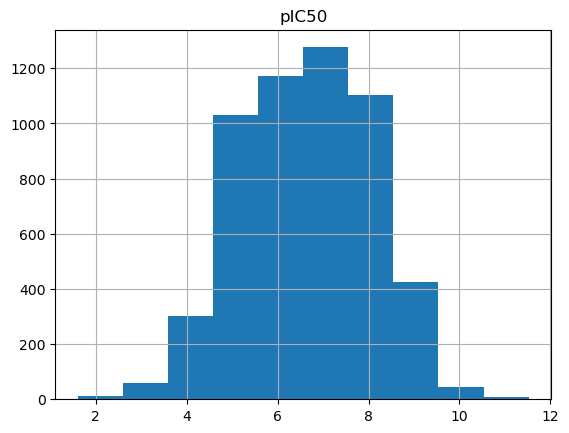

In [105]:
# plot the pIC50 value distribution
output_df.hist(column="pIC50")

In [106]:
output_df.head(1)

,molecule_chembl_id,IC50,units,smiles,pIC50
0,CHEMBL68920,41.0,nM,Cc1cc(C)c(/C=C2\C(=O)Nc3ncnc(Nc4ccc(F)c(Cl)c4)...,7.387216


In [107]:
# Add molecule column
PandasTools.AddMoleculeColumnToFrame(output_df, smilesCol="smiles")
#Converts the smiles column into a ROMol column of RDKit molecule objects, 
#enabling structure-based operations and visualization

In [108]:
output_df.head(1)

,molecule_chembl_id,IC50,units,smiles,pIC50,ROMol
0,CHEMBL68920,41.0,nM,Cc1cc(C)c(/C=C2\C(=O)Nc3ncnc(Nc4ccc(F)c(Cl)c4)...,7.387216,<rdkit.Chem.rdchem.Mol object at 0x000002386C4...


In [109]:
# Sort molecules by pIC50
output_df.sort_values(by='pIC50', ascending=False, inplace=True)

In [110]:
output_df.head(2)

,molecule_chembl_id,IC50,units,smiles,pIC50,ROMol
984,CHEMBL63786,0.003,nM,Brc1cccc(Nc2ncnc3cc4ccccc4cc23)c1,11.522879,<rdkit.Chem.rdchem.Mol object at 0x000002386C4...
675,CHEMBL53711,0.006,nM,CN(C)c1cc2c(Nc3cccc(Br)c3)ncnc2cn1,11.221849,<rdkit.Chem.rdchem.Mol object at 0x000002386C4...


In [111]:
# Reset index
output_df.reset_index(drop=True, inplace=True)

In [112]:
output_df.head(2)

,molecule_chembl_id,IC50,units,smiles,pIC50,ROMol
0,CHEMBL63786,0.003,nM,Brc1cccc(Nc2ncnc3cc4ccccc4cc23)c1,11.522879,<rdkit.Chem.rdchem.Mol object at 0x000002386C4...
1,CHEMBL53711,0.006,nM,CN(C)c1cc2c(Nc3cccc(Br)c3)ncnc2cn1,11.221849,<rdkit.Chem.rdchem.Mol object at 0x000002386C4...


In [113]:
#the three most active molecules--molecules with the highest pIC50 values
##output_df.head(3)
output_df.drop('smiles', axis=1).head(3)

,molecule_chembl_id,IC50,units,pIC50,ROMol
0,CHEMBL63786,0.003,nM,11.522879,<rdkit.Chem.rdchem.Mol object at 0x000002386C4...
1,CHEMBL53711,0.006,nM,11.221849,<rdkit.Chem.rdchem.Mol object at 0x000002386C4...
2,CHEMBL35820,0.006,nM,11.221849,<rdkit.Chem.rdchem.Mol object at 0x000002386C4...


In [114]:
output_df.shape

(5432, 6)

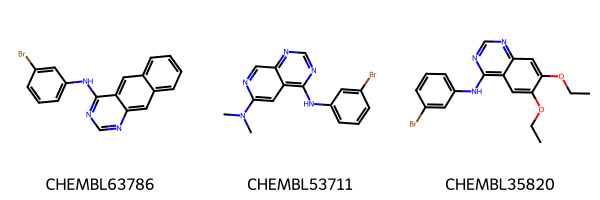

In [115]:
PandasTools.FrameToGridImage(
    output_df.head(3),
    column="ROMol",
    legendsCol="molecule_chembl_id",
    molsPerRow=3,
)

In [116]:
print(f"DataFrame shape: {output_df.shape}")

DataFrame shape: (5432, 6)


In [117]:
# Prepare saving the dataset: Drop the ROMol column--reason for dropping is csv cant store those objects in Romol
output_df = output_df.drop("ROMol", axis=1)

In [118]:
print(f"DataFrame shape: {output_df.shape}")

DataFrame shape: (5432, 5)


##### Freeze output data to ChEMBL 27

In [119]:
import os
os.listdir(r"C:\Users\PC\OneDrive\Attachments\Desktop\Bioinformatics\TeachOpenCADD")

['EGFR_bioactivities_CHEMBL27.csv (1).zip',
 'EGFR_bioactivities_CHEMBL27.csv.zip',
 'EGFR_compounds.csv',
 'EGFR_compounds_ea055ef.csv']

In [120]:
output_df = pd.read_csv(
    r"C:\Users\PC\OneDrive\Attachments\Desktop\Bioinformatics\TeachOpenCADD\EGFR_compounds_ea055ef.csv",
    index_col=0,
    float_precision="round_trip",
)
output_df.head()

,molecule_chembl_id,IC50,units,smiles,pIC50
0,CHEMBL63786,0.003,nM,Brc1cccc(Nc2ncnc3cc4ccccc4cc23)c1,11.522879
1,CHEMBL35820,0.006,nM,CCOc1cc2ncnc(Nc3cccc(Br)c3)c2cc1OCC,11.221849
2,CHEMBL53711,0.006,nM,CN(C)c1cc2c(Nc3cccc(Br)c3)ncnc2cn1,11.221849
3,CHEMBL66031,0.008,nM,Brc1cccc(Nc2ncnc3cc4[nH]cnc4cc23)c1,11.096910
4,CHEMBL53753,0.008,nM,CNc1cc2c(Nc3cccc(Br)c3)ncnc2cn1,11.096910


In [121]:
output_df.head()

,molecule_chembl_id,IC50,units,smiles,pIC50
0,CHEMBL63786,0.003,nM,Brc1cccc(Nc2ncnc3cc4ccccc4cc23)c1,11.522879
1,CHEMBL35820,0.006,nM,CCOc1cc2ncnc(Nc3cccc(Br)c3)c2cc1OCC,11.221849
2,CHEMBL53711,0.006,nM,CN(C)c1cc2c(Nc3cccc(Br)c3)ncnc2cn1,11.221849
3,CHEMBL66031,0.008,nM,Brc1cccc(Nc2ncnc3cc4[nH]cnc4cc23)c1,11.096910
4,CHEMBL53753,0.008,nM,CNc1cc2c(Nc3cccc(Br)c3)ncnc2cn1,11.096910


In [122]:
output_df.to_csv("EGFR_compounds.csv")


In [123]:
output_df.head()

,molecule_chembl_id,IC50,units,smiles,pIC50
0,CHEMBL63786,0.003,nM,Brc1cccc(Nc2ncnc3cc4ccccc4cc23)c1,11.522879
1,CHEMBL35820,0.006,nM,CCOc1cc2ncnc(Nc3cccc(Br)c3)c2cc1OCC,11.221849
2,CHEMBL53711,0.006,nM,CN(C)c1cc2c(Nc3cccc(Br)c3)ncnc2cn1,11.221849
3,CHEMBL66031,0.008,nM,Brc1cccc(Nc2ncnc3cc4[nH]cnc4cc23)c1,11.096910
4,CHEMBL53753,0.008,nM,CNc1cc2c(Nc3cccc(Br)c3)ncnc2cn1,11.096910
